# Part 3 — trends in reported animal disease occurrence

WOAH Datathon, Challenge 6 · 2005–2024

This notebook loads a Parts 1/2 export when available, validates summary selection, runs exploratory aggregation and exports presentation charts and a report. The current repository has no cleaned WAHIS export, so the default is an audited raw fallback. Existing teammate files are untouched.

**Unit:** one selected administrative-division × disease × subtype × country × reporting-semester summary. Sum **New outbreaks**, never row counts, cases or animal units. Counts describe reported contributions rather than incidence or unique biological events across disease labels.

**Selection:** prefer Both animal categories by subtype; otherwise use existing category summaries. Preserve unknown counts and never fabricate missing zeros. Quarantine conflicting keys; remove verified regional copies. Compare Both-only scope in the audit.

**Resolution:** year and reporting semester only. Monthly onset analysis and maps are skipped because occurrence dates and verified geographies are not supplied. No epidemiological causes or validated early warnings are inferred.

Run all cells with dependencies from `requirements.txt`. See `README.md` for execution and the cleaned-export contract.

In [1]:
from pathlib import Path
import sys
from IPython.display import display, Markdown, SVG

ROOT = Path.cwd()
if ROOT.name == 'eda':
    ROOT = ROOT.parent
if not (ROOT / 'WAHIS_data.csv').exists():
    raise RuntimeError('Run from the repository root or eda directory.')
sys.path.insert(0, str(ROOT / 'eda'))
from analysis import run
INPUT = None  # uses data/cleaned_summary.csv if present; otherwise audited raw CSV
POLICY = 'prefer-both'  # alternatively 'both-only'
OUTPUT = ROOT / 'eda/output'


## Load, validate and aggregate

The supporting module checks schema and semester/year consistency, synthetic flags, nonnegative integer counts, subtype grain and disjoint regions. It exports audited aggregates rather than a large derived dataset. Missing periods stay unknown. The analysis screen uses only preceding same-half years, never future observations.

In [2]:
summaries, tables, audit, findings, chart_notes = run(INPUT, OUTPUT, POLICY)
display(Markdown(f"**Input:** {audit['input_mode']} · **Policy:** {POLICY} · **Known counts:** {audit['selected_known_outbreaks']:,.0f}"))
display(tables['annual'])
display(Markdown(f"Unknown summary groups: {audit['selected_unknown_groups']:,}. Verified duplicate rows removed: {audit['verified_duplicate_rows_removed']:,}. Orphan detail groups excluded without zero inference: {audit['detail_groups_without_summary']:,}."))

{
  "input": "/Users/euniceng/Documents/WAHIS-datathon/WAHIS_data.csv",
  "sha256": "3e858a8672a079667fad6ffb6ca72136ef3e766dcc5b96d95c95253a6911b184",
  "input_rows": 657148,
  "policy": "prefer-both",
  "out_of_scope_or_invalid_year_rows": 29428,
  "synthetic_rows_excluded": 0,
  "verified_duplicate_rows_removed": 80622,
  "outbreak_id_rows_excluded": 1738,
  "candidate_summary_rows": 227143,
  "missing_numeric_summary_rows": 55,
  "conflicting_summary_keys_excluded": 0,
  "same_key_same_count_rows_removed": 0,
  "selected_summary_groups": 225379,
  "category_fallback_groups": 44095,
  "both_only_known_outbreaks": 3923628.0,
  "category_fallback_known_outbreaks": 784440.0,
  "selected_unknown_groups": 33,
  "detail_groups_without_summary": 30617,
  "selected_known_outbreaks": 4708068.0,
  "diseases": 155,
  "countries": 197,
  "regions": [
    "Africa",
    "Americas",
    "Asia",
    "Europe",
    "Middle East",
    "Oceania"
  ],
  "input_mode": "audited raw fallback; upstream expo

**Input:** audited raw fallback; upstream export not present · **Policy:** prefer-both · **Known counts:** 4,708,068

,Year,outbreaks,summary_groups,unknown_groups,countries_with_known_counts,yoy_pct
0,2005,153322.0,8891,0,139,NaN
1,2006,162863.0,9173,0,142,6.222851
2,2007,191435.0,10115,0,149,17.543580
3,2008,284945.0,10781,0,154,48.846867
4,2009,242164.0,10646,0,160,-15.013775
5,2010,253390.0,11748,0,165,4.635701
6,2011,688141.0,11995,0,161,171.573858
7,2012,200221.0,11023,0,158,-70.904073
8,2013,229458.0,11540,0,158,14.602364
9,2014,184200.0,11413,0,159,-19.723871


Unknown summary groups: 33. Verified duplicate rows removed: 80,622. Orphan detail groups excluded without zero inference: 30,617.

## 01 annual trend coverage

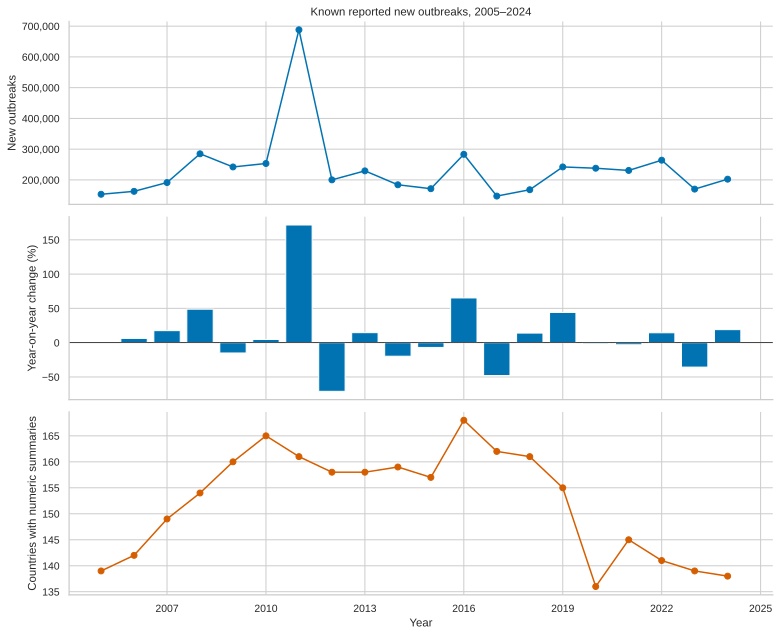

In [3]:
name = '01_annual_trend_coverage'
path = OUTPUT / 'charts' / (name + '.svg')
if path.exists():
    display(SVG(filename=str(path)))
else:
    display(Markdown('No eligible observations; chart skipped.'))

In [4]:
if '01_annual_trend_coverage' in chart_notes:
    note = chart_notes['01_annual_trend_coverage']
    display(Markdown("\n\n".join(f"**{label}:** {value}" for label, value in zip(
        ['Research question', 'Method', 'Observation', 'Interpretation', 'Limitations'], note))))

**Research question:** How do reported counts and coverage change annually?

**Method:** Sum known selected New outbreaks by Year; percentage change uses consecutive observed years without filling missing counts.

**Observation:** 2011 peaks at 688,141; Iran / Paenibacillus larvae (American foulbrood) contributes 66.7% of that total.

**Interpretation:** Use the peak and coverage changes to choose periods for disease-specific review.

**Limitations:** Unknown groups contribute no numeric count; counts may be partial. Country numbers do not measure complete reporting or livestock exposure.

## 02 semester trend

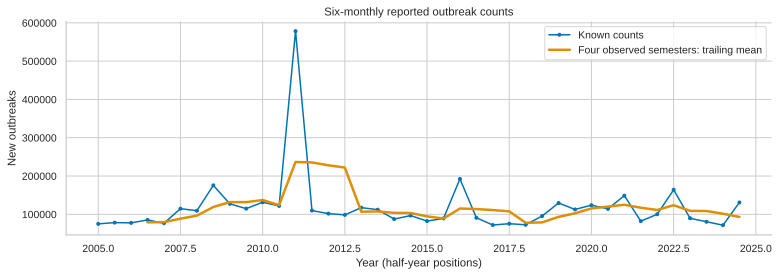

In [5]:
name = '02_semester_trend'
path = OUTPUT / 'charts' / (name + '.svg')
if path.exists():
    display(SVG(filename=str(path)))
else:
    display(Markdown('No eligible observations; chart skipped.'))

In [6]:
if '02_semester_trend' in chart_notes:
    note = chart_notes['02_semester_trend']
    display(Markdown("\n\n".join(f"**{label}:** {value}" for label, value in zip(
        ['Research question', 'Method', 'Observation', 'Interpretation', 'Limitations'], note))))

**Research question:** When do six-month reported counts peak?

**Method:** Sum by explicit reporting semester; add a trailing mean of four observed semesters.

**Observation:** 2024 contains 2 semester labels; country coverage is half 1: 129, half 2: 126.

**Interpretation:** Half-year variation can guide finer data requests.

**Limitations:** These are reporting-period counts; precise onset/report dates and monthly seasonality are unavailable. A trailing mean is descriptive.

## 03 top disease trends

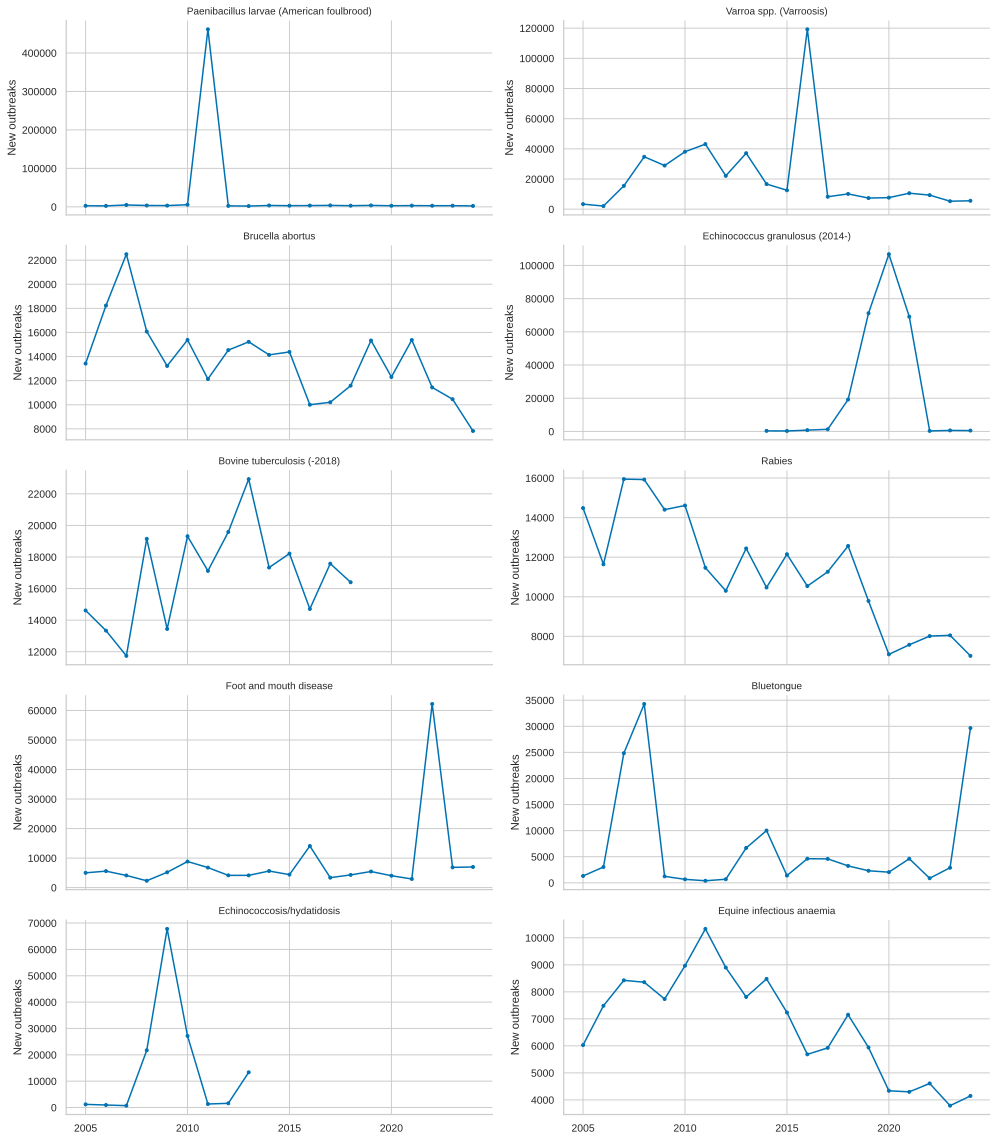

In [7]:
name = '03_top_disease_trends'
path = OUTPUT / 'charts' / (name + '.svg')
if path.exists():
    display(SVG(filename=str(path)))
else:
    display(Markdown('No eligible observations; chart skipped.'))

In [8]:
if '03_top_disease_trends' in chart_notes:
    note = chart_notes['03_top_disease_trends']
    display(Markdown("\n\n".join(f"**{label}:** {value}" for label, value in zip(
        ['Research question', 'Method', 'Observation', 'Interpretation', 'Limitations'], note))))

**Research question:** Are high-count diseases stable or dominated by spikes?

**Method:** Use unmerged top ten source labels and separate annual y-axis scales; missing years remain gaps.

**Observation:** The top ten labels account for 54.0% of known counts. See exported series for exact peaks.

**Interpretation:** Separate scales reveal shapes obscured by the global total.

**Limitations:** Disease definitions change over time; no merged HPAI or tuberculosis continuity is assumed. Counts across disease definitions may not represent unique biological events.

## 04 disease region ranking

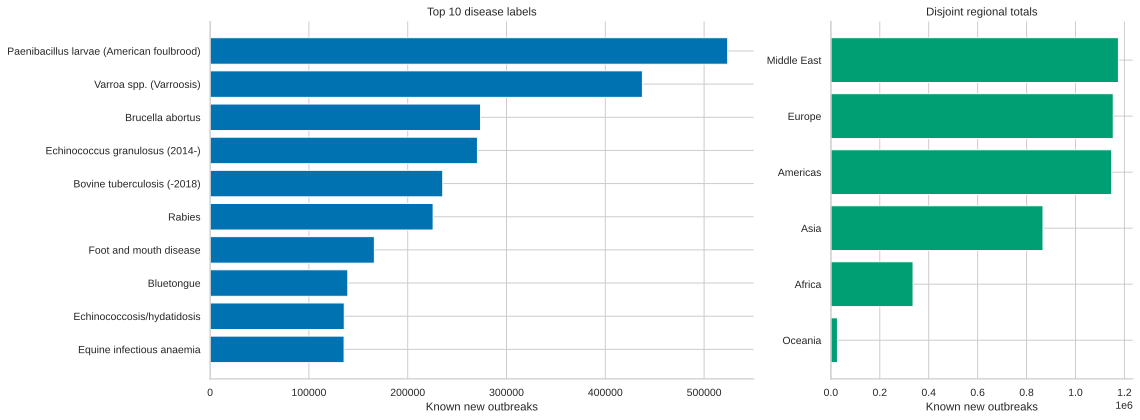

In [9]:
name = '04_disease_region_ranking'
path = OUTPUT / 'charts' / (name + '.svg')
if path.exists():
    display(SVG(filename=str(path)))
else:
    display(Markdown('No eligible observations; chart skipped.'))

In [10]:
if '04_disease_region_ranking' in chart_notes:
    note = chart_notes['04_disease_region_ranking']
    display(Markdown("\n\n".join(f"**{label}:** {value}" for label, value in zip(
        ['Research question', 'Method', 'Observation', 'Interpretation', 'Limitations'], note))))

**Research question:** Which diseases and regions contribute most known counts?

**Method:** Sum known counts after verified duplication removal, subtype-preserving selection and category priority.

**Observation:** Paenibacillus larvae (American foulbrood) and Middle East lead their rankings.

**Interpretation:** Prioritise these contributors for source verification and targeted analysis.

**Limitations:** Reported counts reflect reporting and heterogeneous outbreak definitions, not underlying risk; bee animal units must not be confused with outbreak counts.

## 05 region trends

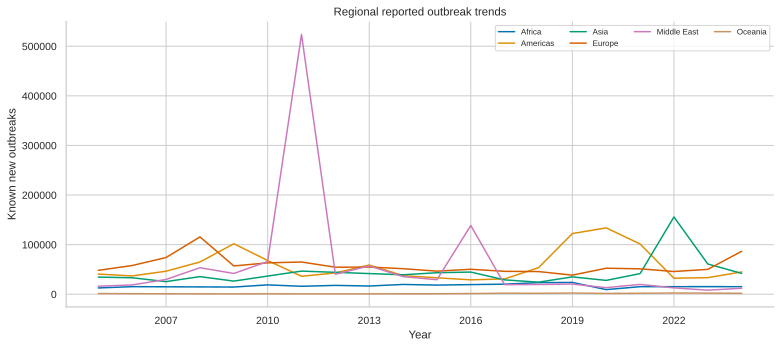

In [11]:
name = '05_region_trends'
path = OUTPUT / 'charts' / (name + '.svg')
if path.exists():
    display(SVG(filename=str(path)))
else:
    display(Markdown('No eligible observations; chart skipped.'))

In [12]:
if '05_region_trends' in chart_notes:
    note = chart_notes['05_region_trends']
    display(Markdown("\n\n".join(f"**{label}:** {value}" for label, value in zip(
        ['Research question', 'Method', 'Observation', 'Interpretation', 'Limitations'], note))))

**Research question:** Do regions show different temporal patterns?

**Method:** Annual regional sums with missing region-years left as gaps.

**Observation:** The largest cumulative regional share is Middle East (25.0%).

**Interpretation:** Review regional peaks separately rather than infer a single global trajectory.

**Limitations:** Country participation and administrative coverage vary; regional totals lack population denominators.

## 06 disease region heatmap

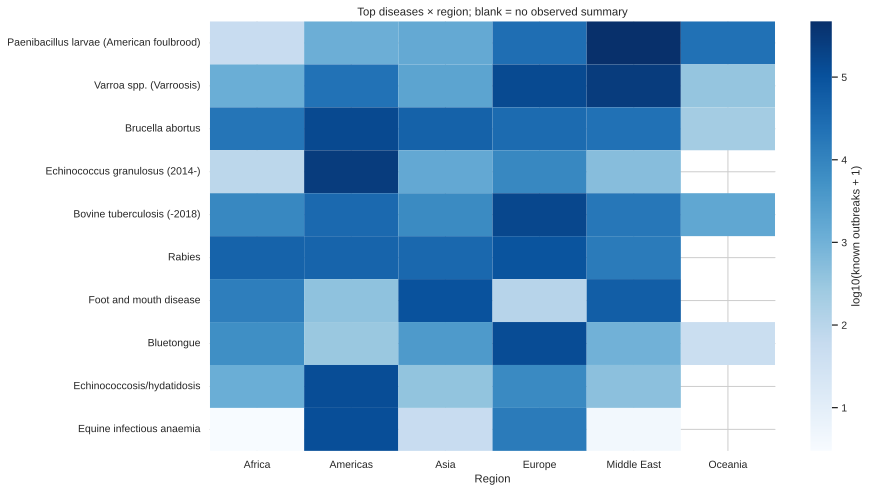

In [13]:
name = '06_disease_region_heatmap'
path = OUTPUT / 'charts' / (name + '.svg')
if path.exists():
    display(SVG(filename=str(path)))
else:
    display(Markdown('No eligible observations; chart skipped.'))

In [14]:
if '06_disease_region_heatmap' in chart_notes:
    note = chart_notes['06_disease_region_heatmap']
    display(Markdown("\n\n".join(f"**{label}:** {value}" for label, value in zip(
        ['Research question', 'Method', 'Observation', 'Interpretation', 'Limitations'], note))))

**Research question:** Which top diseases dominate where?

**Method:** Known disease-region counts on log10(count+1); blanks are unobserved, explicit zero remains zero.

**Observation:** Paenibacillus larvae (American foulbrood) is the highest-count source disease label overall.

**Interpretation:** Log colour supports comparison across large differences in scale.

**Limitations:** Colour does not indicate adjusted risk or establish disease absence in blank cells.

## 07 region composition

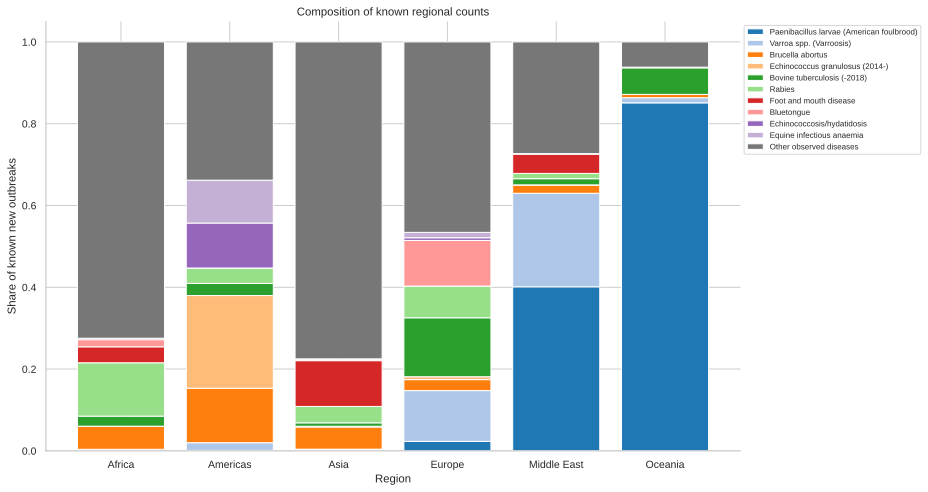

In [15]:
name = '07_region_composition'
path = OUTPUT / 'charts' / (name + '.svg')
if path.exists():
    display(SVG(filename=str(path)))
else:
    display(Markdown('No eligible observations; chart skipped.'))

In [16]:
if '07_region_composition' in chart_notes:
    note = chart_notes['07_region_composition']
    display(Markdown("\n\n".join(f"**{label}:** {value}" for label, value in zip(
        ['Research question', 'Method', 'Observation', 'Interpretation', 'Limitations'], note))))

**Research question:** How does the disease mix differ across regions?

**Method:** Shares of each regional known-count total: top ten labels plus all other observed disease labels.

**Observation:** Top ten labels contribute 54.0% globally; regional mixes are in disease_region.csv.

**Interpretation:** Composition is useful for choosing regional disease case studies.

**Limitations:** Shares condition on known counts. Blank combinations add no observed contribution; this does not impute disease absence.

## 08 disease year heatmap

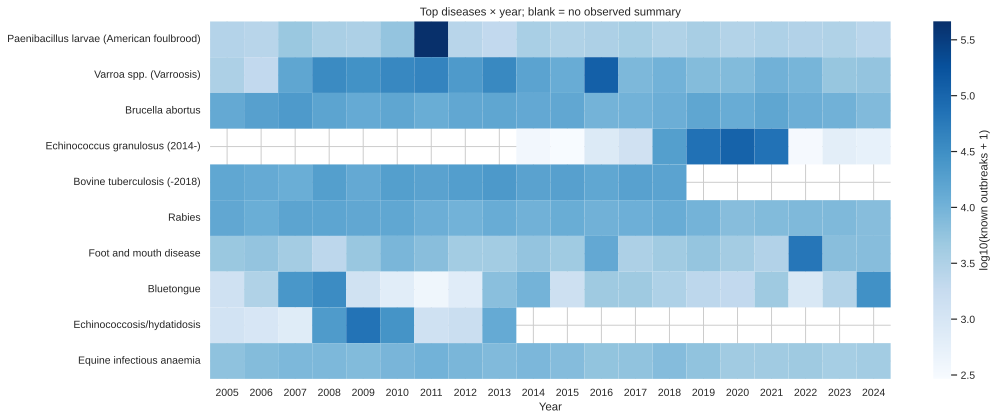

In [17]:
name = '08_disease_year_heatmap'
path = OUTPUT / 'charts' / (name + '.svg')
if path.exists():
    display(SVG(filename=str(path)))
else:
    display(Markdown('No eligible observations; chart skipped.'))

In [18]:
if '08_disease_year_heatmap' in chart_notes:
    note = chart_notes['08_disease_year_heatmap']
    display(Markdown("\n\n".join(f"**{label}:** {value}" for label, value in zip(
        ['Research question', 'Method', 'Observation', 'Interpretation', 'Limitations'], note))))

**Research question:** Which high-count diseases have abrupt peaks or changing label coverage?

**Method:** Log10 annual sums for unchanged top source labels, with gaps retained.

**Observation:** The global count peak is 2011; each disease may peak in a different year.

**Interpretation:** Compare concentrated spikes with sustained patterns before selecting a model.

**Limitations:** Renamed or newly introduced labels may create structural gaps; missing data are not zero.

## 09 half year patterns

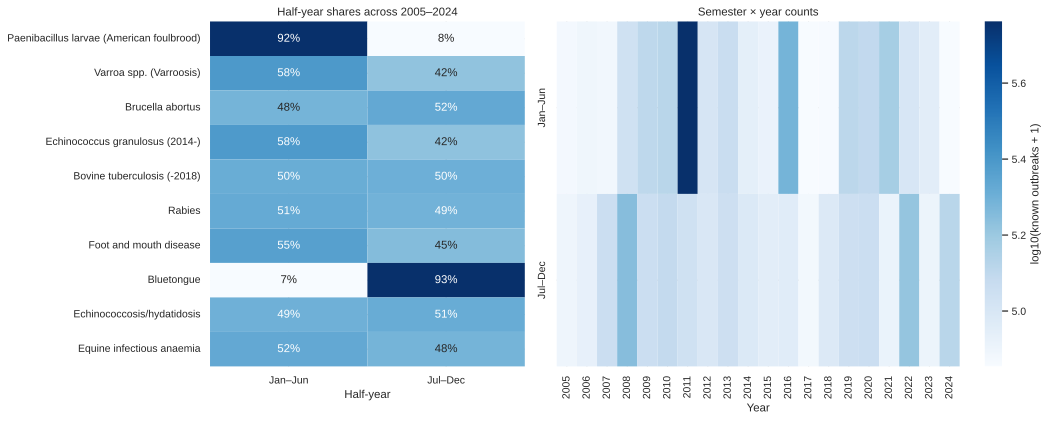

In [19]:
name = '09_half_year_patterns'
path = OUTPUT / 'charts' / (name + '.svg')
if path.exists():
    display(SVG(filename=str(path)))
else:
    display(Markdown('No eligible observations; chart skipped.'))

In [20]:
if '09_half_year_patterns' in chart_notes:
    note = chart_notes['09_half_year_patterns']
    display(Markdown("\n\n".join(f"**{label}:** {value}" for label, value in zip(
        ['Research question', 'Method', 'Observation', 'Interpretation', 'Limitations'], note))))

**Research question:** Is the reporting-period distribution uneven?

**Method:** Pool known counts by Jan–Jun and Jul–Dec for top diseases; show semester-year totals separately.

**Observation:** Bluetongue has 92.7% of known counts in Jul–Dec. Shares describe reporting periods, not monthly onset seasonality.

**Interpretation:** Use these contrasts to design region-specific seasonal follow-up.

**Limitations:** Pooled hemispheres, reporting lag, one-off peaks, and incomplete coverage can mimic seasonality. No monthly or significance claim is supported.

## 10 exploratory anomalies

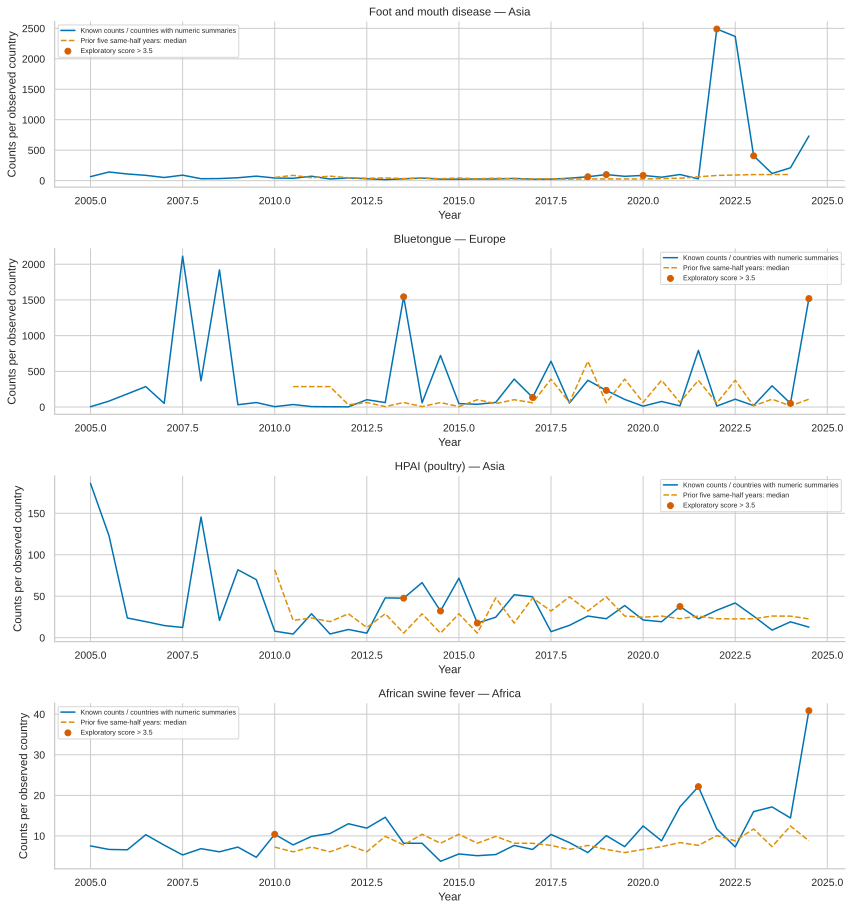

In [21]:
name = '10_exploratory_anomalies'
path = OUTPUT / 'charts' / (name + '.svg')
if path.exists():
    display(SVG(filename=str(path)))
else:
    display(Markdown('No eligible observations; chart skipped.'))

In [22]:
if '10_exploratory_anomalies' in chart_notes:
    note = chart_notes['10_exploratory_anomalies']
    display(Markdown("\n\n".join(f"**{label}:** {value}" for label, value in zip(
        ['Research question', 'Method', 'Observation', 'Interpretation', 'Limitations'], note))))

**Research question:** Which recent semester counts depart from their historical same-half baseline?

**Method:** Prior five consecutive same-half years only; log1p(known counts / disease-specific observed countries), median and scaled MAD; screen positive robust scores >3.5. Skip incomplete-count periods and zero MAD.

**Observation:** 467 flags among 6425 eligible comparisons. The figure prioritises selected diseases with at least three observed countries and 50 known counts, one region per disease. For Asia/FMD 2022 half 1, observed counts per reporting country are 2,488.8 versus historical median 85.5 (29.1×); Indonesia contributes 32,078 known counts.

**Interpretation:** Use flags as a reproducible triage list for source review; five points are too few for calibrated tail probabilities.

**Limitations:** No p-values, false-positive calibration, causal inference or forecast validation. Country composition may change, denominator is a reporting proxy, and excluded ambiguous groups can lower counts.

## 11 country ranking

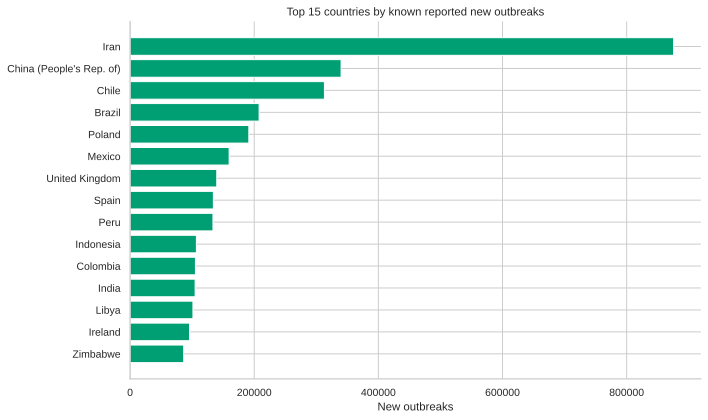

In [23]:
name = '11_country_ranking'
path = OUTPUT / 'charts' / (name + '.svg')
if path.exists():
    display(SVG(filename=str(path)))
else:
    display(Markdown('No eligible observations; chart skipped.'))

In [24]:
if '11_country_ranking' in chart_notes:
    note = chart_notes['11_country_ranking']
    display(Markdown("\n\n".join(f"**{label}:** {value}" for label, value in zip(
        ['Research question', 'Method', 'Observation', 'Interpretation', 'Limitations'], note))))

**Research question:** Are known counts concentrated in a few countries?

**Method:** Rank cumulative known country counts after regional de-duplication.

**Observation:** The top five countries account for 41.0%.

**Interpretation:** Concentration motivates country-level sensitivity checks.

**Limitations:** No livestock denominators, comparable surveillance capacity or uniform outbreak definition.

## 12 priority disease regions

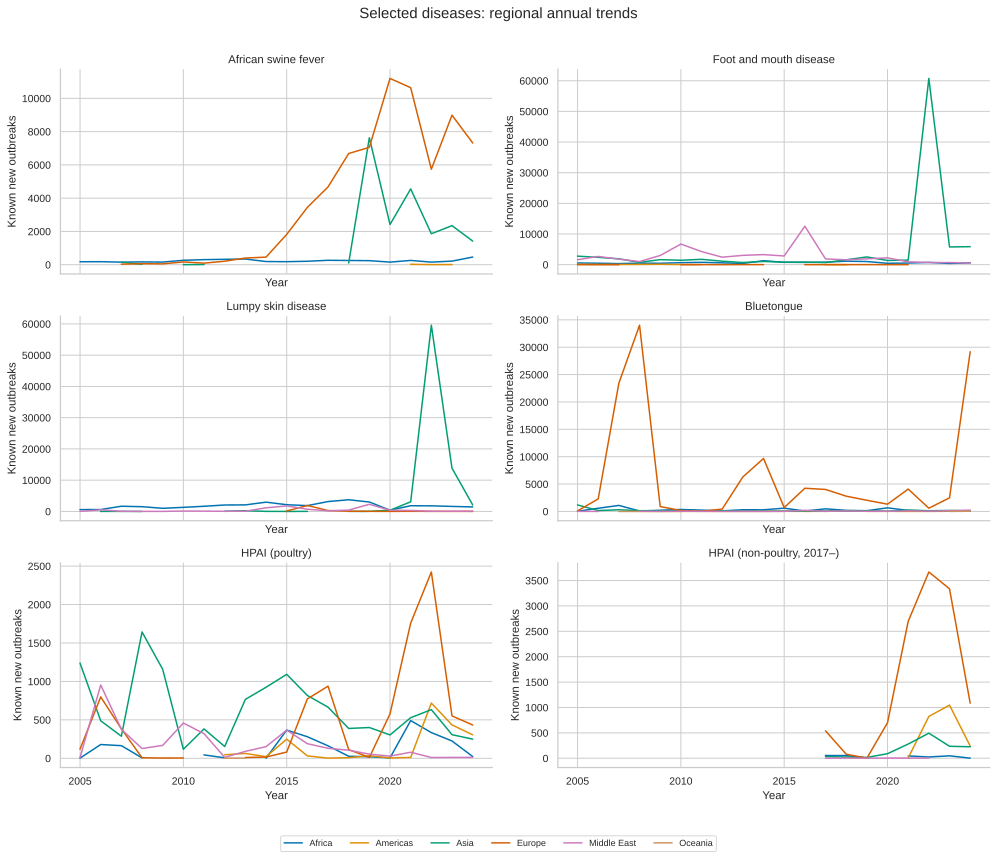

In [25]:
name = '12_priority_disease_regions'
path = OUTPUT / 'charts' / (name + '.svg')
if path.exists():
    display(SVG(filename=str(path)))
else:
    display(Markdown('No eligible observations; chart skipped.'))

In [26]:
if '12_priority_disease_regions' in chart_notes:
    note = chart_notes['12_priority_disease_regions']
    display(Markdown("\n\n".join(f"**{label}:** {value}" for label, value in zip(
        ['Research question', 'Method', 'Observation', 'Interpretation', 'Limitations'], note))))

**Research question:** Which regions drive changes in selected diseases?

**Method:** Separate annual regional sums for six observed source disease labels; HPAI categories remain separate; no absent years are filled.

**Observation:** Peak observed global years: African swine fever: 2021 (15,477); Foot and mouth disease: 2022 (62,180); Lumpy skin disease: 2022 (61,433); Bluetongue: 2008 (34,276); HPAI (poultry): 2022 (4,118); HPAI (non-poultry, 2017–): 2022 (5,014).

**Interpretation:** These peaks identify focused disease-region case studies for Challenge 6.

**Limitations:** Coverage and source definitions change; the non-poultry HPAI label begins in 2017 and cannot be compared with an invented pre-2017 zero baseline.

## Changing disease counts: observed and fixed-country sensitivity

Compare five-year totals in 2005–09 and 2020–24. The fixed-country set includes only countries with numeric selected summaries in every one of the ten comparison years. This does **not** guarantee all subnational groups or both semesters were reported. No statistical significance is claimed. Original labels are retained, so definition changes create genuine breaks in comparability.

In [27]:
display(tables['disease_changes'].sort_values('change_pct', ascending=False).head(20))

,Disease,early_2005_09,late_2020_24,change_pct,fixed_countries,fixed_early,fixed_late,fixed_change_pct
53,Epizootic hemorrhagic disease virus (Inf. with),1.0,2138.0,213700.000000,0,0.0,0.0,NaN
150,Western equine encephalitis virus (Inf. with) ...,8.0,1485.0,18462.500000,0,0.0,0.0,NaN
5,African swine fever virus (Inf. with),1353.0,57768.0,4169.623060,1,51.0,157.0,207.843137
16,Batrachochytrium dendrobatidis (Inf. with)(2009-),10.0,314.0,3040.000000,0,0.0,0.0,NaN
3,Aethina tumida (Inf. with)(Small hive beetle)(...,28.0,712.0,2442.857143,0,0.0,0.0,NaN
87,Lumpy skin disease virus (Inf. with),5957.0,86940.0,1359.459459,4,1543.0,1542.0,-0.064809
118,Red sea bream iridovirus (Inf. with) (-2024),71.0,823.0,1059.154930,0,0.0,0.0,NaN
75,Infectious haematopoietic necrosis virus (Inf....,105.0,898.0,755.238095,1,32.0,148.0,362.500000
30,Brucella suis (Inf. with),282.0,2295.0,713.829787,0,0.0,0.0,NaN
8,Aphanomyces invadans (Inf. with) (Epizootic ul...,42.0,328.0,680.952381,0,0.0,0.0,NaN


## Exploratory review list

Known counts divided by disease-specific countries with numeric summaries are compared with the previous five same-half years on a log1p scale. A robust score above 3.5 is an exploratory screen. Zero historical MAD, missing historical years and groups with unknown counts are skipped. Five historical points cannot calibrate a tail probability. Changing reporter composition, tiny MAD and small denominators can yield high scores: use the exported baseline country range to triage each flag.

In [28]:
display(tables['anomaly_flags'].head(20))

,Disease,World region,Year,half,outbreaks,countries,baseline_per_country,observed_per_country,robust_score,exploratory_flag,baseline_countries_min,baseline_countries_max,largest_contributing_country,largest_country_known_counts,fold_vs_baseline
2333,Duck virus hepatitis,Asia,2023,2,116.0,1,30.666667,116.000000,84.182315,True,2,3,China (People's Rep. of),116.0,3.782609
4252,Newcastle disease virus (Inf. with),Americas,2014,2,126.0,5,3.428571,25.200000,74.937796,True,4,8,Colombia,61.0,7.350000
6054,Tularemia,Europe,2019,2,155.0,9,8.777778,17.222222,64.452959,True,6,9,Germany,126.0,1.962025
4057,Mycoplasma gallisepticum (Inf. with) (Avian my...,Europe,2013,1,70.0,4,2.666667,17.500000,59.493530,True,4,6,Spain,62.0,6.562500
6056,Tularemia,Europe,2020,2,106.0,7,8.777778,15.142857,51.908351,True,6,9,Germany,63.0,1.725136
1500,Brucella abortus (Inf. with),Europe,2023,1,1105.0,6,68.571429,184.166667,40.522597,True,5,7,Greece,652.0,2.685764
4254,Newcastle disease virus (Inf. with),Americas,2015,2,109.0,5,3.500000,21.800000,38.851640,True,5,8,Peru,61.0,6.228571
3363,Infectious bursal disease (Gumboro disease),Middle East,2021,2,376.0,1,11.000000,376.000000,38.354021,True,2,4,Iran,376.0,34.181818
6156,Varroa spp. (Inf. of honey bees with) (Varroosis),Asia,2014,1,115.0,2,5.500000,57.500000,37.786352,True,2,4,Malaysia,92.0,10.454545
2114,Contagious agalactia,Europe,2017,2,64.0,2,11.500000,32.000000,33.065381,True,3,5,Italy,33.0,2.782609


## Climate feasibility

Existing country-month climate values are joined only after six complete months per semester. A high match percentage establishes join feasibility, not association. Shared ISO3 mappings for countries/territories need adjudication. Country fixed effects, contiguous lagged anomalies, reporting denominators and training-only temporal validation are suggested follow-ups. No climate downloads or upstream changes are made.

In [29]:
display(audit['climate'])

{'status': 'Audited join only; no association or predictive claims.',
 'observed_country_semesters': 5793,
 'complete_climate_matches': 5756,
 'match_pct': 99.36129811841879,
 'unmatched_countries': ['Cayman Islands',
  'French Guiana',
  'Guadeloupe',
  'Martinique',
  'Mayotte',
  'Reunion'],
 'shared_iso3_codes': [{'Country': 'Ceuta', 'iso3': 'ESP'},
  {'Country': 'Melilla', 'iso3': 'ESP'},
  {'Country': 'Serbia', 'iso3': 'SRB'},
  {'Country': 'Serbia and Montenegro', 'iso3': 'SRB'},
  {'Country': 'Spain', 'iso3': 'ESP'}]}

## Supported insights and Challenge 6 relevance

In [30]:
display(Markdown("\n\n".join(f"{i}. {v}" for i, v in enumerate(findings, 1))))

1. The largest country-disease contribution in the peak year is Iran: Paenibacillus larvae (American foulbrood), 459,127 (66.7% of 2011 known counts). This source entry needs verification before an epidemiological explanation.

2. The highest annual known count is 2011 (688,141); this is a reported-count peak, not an incidence estimate.

3. Paenibacillus larvae (American foulbrood) leads the disease ranking (523,909); the top ten labels contribute 54.0% of known counts.

4. Middle East contributes the largest regional share (25.0%); regions are disjoint after verified duplicate removal.

5. Iran has the highest known country count (875,688); the top five countries contribute 41.0%.

6. Countries with numeric summary counts vary from 136 to 168 annually; coverage limits trend interpretation.

7. Category fallback adds 784,440 known counts beyond Both-only summaries (3,923,628); this sensitivity materially affects scope.

8. The trailing same-half log-MAD screen flags 467 of 6425 eligible disease-region-semesters; these are candidates for review, not validated significant changes.

9. Bluetongue has 92.7% of known counts in Jul–Dec; this is pooled half-year reporting asymmetry, not confirmed monthly onset seasonality.

10. ASF known totals increase from 1,353 in 2005–09 to 57,768 in 2020–24 (+4,169.6%). Only 1 country has numeric summaries in every comparison year: changing participation prevents a broad fixed-country trend claim.

The annual and regional plots address trends; coverage and selection sensitivity distinguish measurement shifts from epidemiological hypotheses. The historical baseline offers reproducible candidates for review, without claiming statistically validated changes or predictive utility.

**Integration:** Parts 1/2 should export `data/cleaned_summary.csv` using the original column names, subtype and category fields, preserving unknown counts and synthetic flags. A Both-only export changes scope. Confirm subtype additivity and category policy with the team before adopting presentation totals.

**Next steps:** verify extreme source reports and the WOAH data dictionary; reconcile historical disease definitions; test disease/region trends with overdispersed count models and reporting/exposure denominators; assess half-year patterns by hemisphere; request onset dates for monthly analyses; evaluate climate with fixed effects and time-ordered predictive holdouts.

Outputs: `report.md`, `output/audit.json`, `output/tables/`, and 300-dpi PNG/editable SVG charts in `output/charts/`.